In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

In [41]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/loan_approval_20000.csv")

In [42]:
df.head()

,Applicant_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,APP000001,Male,No,1,Graduate,No,86082,0,389.0,180,1.0,Urban,Approved
1,APP000002,Male,Yes,0,Graduate,No,24335,7846,138.0,360,1.0,Urban,Approved
2,APP000003,Female,Yes,1,Graduate,No,17321,10511,20.0,420,1.0,Urban,Approved
3,APP000004,Female,Yes,0,Not Graduate,No,78035,1015,269.0,240,1.0,Semiurban,Approved
4,APP000005,Female,Yes,0,Not Graduate,No,25057,6006,87.0,360,1.0,Urban,Rejected


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Applicant_ID       20000 non-null  object 
 1   Gender             19791 non-null  object 
 2   Married            20000 non-null  object 
 3   Dependents         19708 non-null  object 
 4   Education          20000 non-null  object 
 5   Self_Employed      19787 non-null  object 
 6   ApplicantIncome    20000 non-null  int64  
 7   CoapplicantIncome  20000 non-null  int64  
 8   LoanAmount         19811 non-null  float64
 9   Loan_Amount_Term   20000 non-null  int64  
 10  Credit_History     19601 non-null  float64
 11  Property_Area      20000 non-null  object 
 12  Loan_Status        20000 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [44]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,20000.000000,20000.000000,19811.000000,20000.000000,19601.000000
mean,47630.306350,6806.301900,203.205643,319.464000,0.822254
std,24397.358344,11574.656248,119.630190,73.920403,0.382309
min,12000.000000,0.000000,20.000000,120.000000,0.000000
25%,30506.000000,0.000000,118.000000,300.000000,1.000000
50%,42462.000000,1633.000000,180.000000,360.000000,1.000000
75%,58451.000000,9501.250000,263.000000,360.000000,1.000000
max,250000.000000,150000.000000,700.000000,420.000000,1.000000


In [45]:
df.isnull().sum()

Applicant_ID           0
Gender               209
Married                0
Dependents           292
Education              0
Self_Employed        213
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount           189
Loan_Amount_Term       0
Credit_History       399
Property_Area          0
Loan_Status            0
dtype: int64

In [46]:
df["Gender"].value_counts()

Gender
Male      13530
Female     6261
Name: count, dtype: int64

In [47]:
df["Married"].value_counts()

Married
Yes    13028
No      6972
Name: count, dtype: int64

In [48]:
df["Education"].value_counts()

Education
Graduate        15632
Not Graduate     4368
Name: count, dtype: int64

In [49]:
df["Loan_Status"].value_counts()

Loan_Status
Approved    16593
Rejected     3407
Name: count, dtype: int64

In [50]:
df["Gender"]=df["Gender"].fillna(df["Gender"].mode()[0])
df["Dependents"]=df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"]=df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])
df["LoanAmount"]=df["LoanAmount"].fillna(df["LoanAmount"].mean())
df["Credit_History"]=df["Credit_History"].fillna(df["Credit_History"].mean())

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Applicant_ID       20000 non-null  object 
 1   Gender             20000 non-null  object 
 2   Married            20000 non-null  object 
 3   Dependents         20000 non-null  object 
 4   Education          20000 non-null  object 
 5   Self_Employed      20000 non-null  object 
 6   ApplicantIncome    20000 non-null  int64  
 7   CoapplicantIncome  20000 non-null  int64  
 8   LoanAmount         20000 non-null  float64
 9   Loan_Amount_Term   20000 non-null  int64  
 10  Credit_History     20000 non-null  float64
 11  Property_Area      20000 non-null  object 
 12  Loan_Status        20000 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [52]:
df.duplicated().sum()

np.int64(0)

In [53]:
df.head()

,Applicant_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,APP000001,Male,No,1,Graduate,No,86082,0,389.0,180,1.0,Urban,Approved
1,APP000002,Male,Yes,0,Graduate,No,24335,7846,138.0,360,1.0,Urban,Approved
2,APP000003,Female,Yes,1,Graduate,No,17321,10511,20.0,420,1.0,Urban,Approved
3,APP000004,Female,Yes,0,Not Graduate,No,78035,1015,269.0,240,1.0,Semiurban,Approved
4,APP000005,Female,Yes,0,Not Graduate,No,25057,6006,87.0,360,1.0,Urban,Rejected


# Separate Features and Target

In [64]:
X = df.drop(["Loan_Status", "Applicant_ID"], axis=1)

y = df["Loan_Status"].map({
    "Rejected": 0,
    "Approved": 1
})

# Identify numerical and categorical columns

In [73]:
num_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


# Train-test split

In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 11)
(4000, 11)
(16000,)
(4000,)


In [80]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Build Gradient Boosting model

In [86]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

model = Pipeline([
    ("preprocessing", preprocessing),
    ("model", gb_model)
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Gender','Married','Dependents',...,'Loan_Amount_Term','Credit_History', 'Property_Area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='

In [87]:
y_pred=model.predict(X_test)

# Evaluation metrics

In [89]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy_Score:",accuracy)

Accuracy_Score: 0.842


In [91]:
from sklearn.metrics import precision_score
precision=precision_score(y_test,y_pred)
print("Precision_Score:",precision)

Precision_Score: 0.865578231292517


In [94]:
from sklearn.metrics import recall_score
recall=recall_score(y_test,y_pred)
print("Recall_Score:",recall)

Recall_Score: 0.9584212112081952


In [96]:
from sklearn.metrics import f1_score
f1=f1_score(y_test,y_pred)
print("F1_Score:",f1)

F1_Score: 0.909636831569917


In [98]:
from sklearn.metrics import roc_auc_score
roc=roc_auc_score(y_test,y_pred)
print("Roc_auc_Score:",roc)

Roc_auc_Score: 0.6165086966466821


In [99]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.58      0.27      0.37       681
           1       0.87      0.96      0.91      3319

    accuracy                           0.84      4000
   macro avg       0.72      0.62      0.64      4000
weighted avg       0.82      0.84      0.82      4000



# Confusion matrix

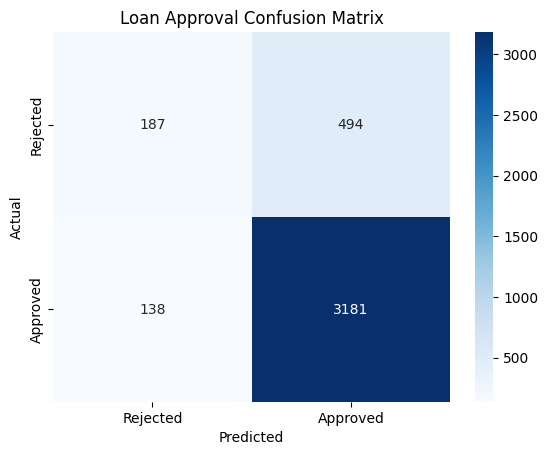

In [100]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Loan Approval Confusion Matrix")
plt.show()

# ROC Curve

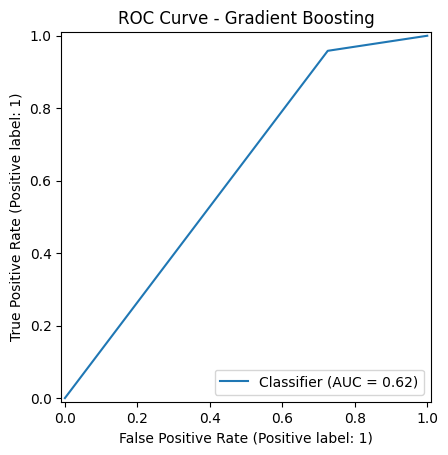

In [102]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_test, y_pred)
plt.title("ROC Curve - Gradient Boosting")
plt.show()

In [103]:
# Feature Importance


In [104]:
feature_names = model.named_steps["preprocessing"].get_feature_names_out()
importances = model.named_steps["model"].feature_importances_
feature_importance = pd.DataFrame({"Feature": feature_names,"Importance": importances})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
feature_importance.head(10)

,Feature,Importance
4,num__Credit_History,0.821341
0,num__ApplicantIncome,0.059718
2,num__LoanAmount,0.048539
1,num__CoapplicantIncome,0.022004
17,cat__Property_Area_Rural,0.012729
18,cat__Property_Area_Semiurban,0.010827
14,cat__Education_Not Graduate,0.006472
13,cat__Education_Graduate,0.005842
3,num__Loan_Amount_Term,0.004384
12,cat__Dependents_3+,0.001837


#  Feature importance visualization

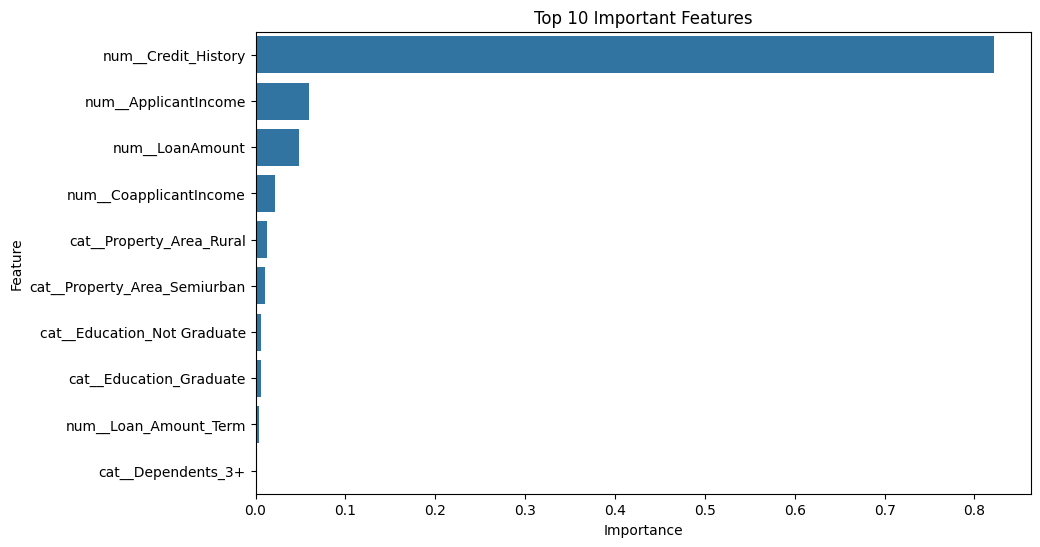

In [105]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature")
plt.title("Top 10 Important Features")
plt.show()

# New applicant prediction

In [107]:
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "1",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 50000,
    "CoapplicantIncome": 20000,
    "LoanAmount": 150,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"}])

prediction = model.predict(new_applicant)[0]
probability = model.predict_proba(new_applicant)[0][1]
print("Loan Status:", "Approved" if prediction == 1 else "Rejected")
print("Approval Probability:", round(probability * 100, 2), "%")

Loan Status: Approved
Approval Probability: 92.48 %


# Save model

In [111]:
import joblib
joblib.dump(model,"loan_approval_gradient_boosting.pkl")
print("Model saved successfully!")

Model saved successfully!
